# D1 Data Analysis Report

## Script for Descriptive Analysis

In [2]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Read the dataset
df = pd.read_csv("Airbnb_NYC_2019.csv")

# Display the first 5 rows
df.head()

# Create a descriptive statistics function
def Desc_stat(sample, field):
    mean = sample[field].mean()
    median = sample[field].median()
    std_dev = sample[field].std()

    return {
        "Average": mean,
        "Median": median,
        "Standard Deviation": std_dev
    }

Desc_stat(df, "price")

{'Average': np.float64(152.7206871868289),
 'Median': np.float64(106.0),
 'Standard Deviation': np.float64(240.15416974718758)}

## Random Sampling

In [3]:
random_sample = df.sample(n=150, random_state=10)

Desc_stat(random_sample, "price")

{'Average': np.float64(140.30666666666667),
 'Median': np.float64(110.0),
 'Standard Deviation': np.float64(105.65284082337405)}

## Sstematic Sampling

In [4]:
# Systematic sampling based on a condition
systematic_sample = df[
    df["availability_365"] > df["availability_365"].mean()
]

# Display the sample
systematic_sample

# Apply the descriptive statistics function to Price
Desc_stat(systematic_sample, "price")

{'Average': np.float64(175.28430266902959),
 'Median': np.float64(120.0),
 'Standard Deviation': np.float64(282.98807375454487)}

In [5]:
# Systematic Sampling - Every 5th Row

# Select every 5th row from the Airbnb NYC dataset
systematic_sample_5 = df.iloc[::5]

# Display the sample
systematic_sample_5

# Apply descriptive statistics to Price
Desc_stat(systematic_sample_5, "price")

{'Average': np.float64(155.11667859699355),
 'Median': np.float64(105.0),
 'Standard Deviation': np.float64(240.24723235001687)}

## Descriptive Statistical Report 

In [6]:
# Detailed descriptive statistics for the dependent variable
df["price"].describe()

count    48895.000000
mean       152.720687
std        240.154170
min          0.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64

## Visualisation through Various Charts 

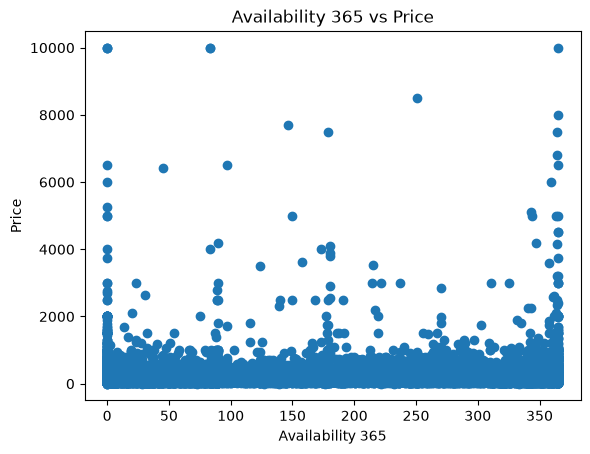

In [7]:
# Scatter Plot
plt.scatter(df["availability_365"], df["price"])

plt.xlabel("Availability 365")
plt.ylabel("Price")
plt.title("Availability 365 vs Price")

plt.show()

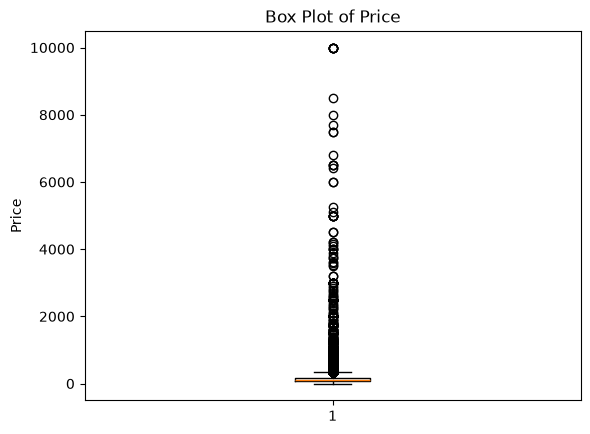

In [8]:
# Box Plot
plt.boxplot(df["price"])

plt.ylabel("Price")
plt.title("Box Plot of Price")

plt.show()


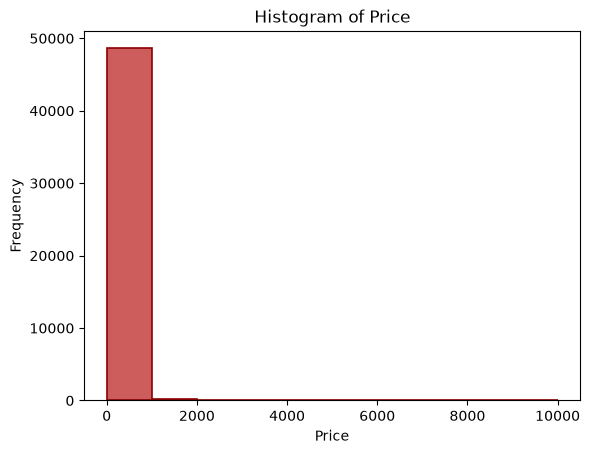

In [9]:
# Histogram
plt.hist(
    df["price"],
    color="indianred",
    edgecolor="darkred",
    linewidth=1.2
)

plt.xlabel("Price")
plt.ylabel("Frequency")
plt.title("Histogram of Price")

plt.show()

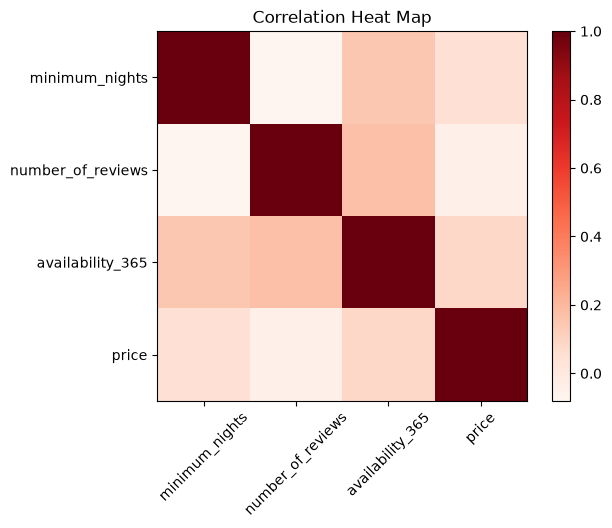

In [10]:
# Select numerical variables
numeric_data = df[
    ["minimum_nights",
     "number_of_reviews",
     "availability_365",
     "price"]
]

# Calculate correlation matrix
correlation = numeric_data.corr()

# Heat Map
plt.imshow(correlation, cmap="Reds")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.colorbar()
plt.title("Correlation Heat Map")

plt.show()

## Hypothesis test

In [11]:
# Pearson Correlation
from scipy import stats

pearson_r, p_value = stats.pearsonr(
    df["availability_365"],
    df["price"]
)

print("Pearson Correlation:", pearson_r)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0 - There is a significant correlation between Availability 365 and Price.")
else:
    print("Fail to reject H0 - There is no significant correlation between Availability 365 and Price.")

Pearson Correlation: 0.08182882742168794
P-value: 2.0567432704087555e-73
Reject H0 - There is a significant correlation between Availability 365 and Price.


In [12]:
# Spearman Correlation
spearman_r, p_value = stats.spearmanr(
    df["availability_365"],
    df["price"]
)

print("Spearman Correlation:", spearman_r)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0 - There is a significant correlation between Availability 365 and Price.")
else:
    print("Fail to reject H0 - There is no significant correlation between Availability 365 and Price.")

Spearman Correlation: 0.0860876776915564
P-value: 4.413696760667561e-81
Reject H0 - There is a significant correlation between Availability 365 and Price.


## One Sample T-test 

In [13]:
# Calculate the population mean of Price
population_mean = df["price"].mean()

# One-Sample T-test
t_stat, p_value = stats.ttest_1samp(
    random_sample["price"],
    population_mean
)

print("Population Mean:", population_mean)
print("Sample Mean:", random_sample["price"].mean())
print("T-statistic:", t_stat)
print("P-value:", p_value)

# Decision
if p_value < 0.05:
    print("Reject H0 - The sample mean is significantly different from the population mean.")
else:
    print("Fail to reject H0 - The sample mean is not significantly different from the population mean.")




Population Mean: 152.7206871868289
Sample Mean: 140.30666666666667
T-statistic: -1.4390533985580252
P-value: 0.15223280518456145
Fail to reject H0 - The sample mean is not significantly different from the population mean.


# D2 ML Report

## Preprocessing

### 1.Data collection

In [14]:
# Data Collection
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

dataset = pd.read_csv("Airbnb_NYC_2019.csv")
X = dataset[["minimum_nights", "number_of_reviews", "reviews_per_month","availability_365", "room_type", "neighbourhood_group"]]
y = dataset["price"]

print(X.head())
print(y.head())

   minimum_nights  number_of_reviews  reviews_per_month  availability_365  \
0               1                  9               0.21               365   
1               1                 45               0.38               355   
2               3                  0                NaN               365   
3               1                270               4.64               194   
4              10                  9               0.10                 0   

         room_type neighbourhood_group  
0     Private room            Brooklyn  
1  Entire home/apt           Manhattan  
2     Private room           Manhattan  
3  Entire home/apt            Brooklyn  
4  Entire home/apt           Manhattan  
0    149
1    225
2    150
3     89
4     80
Name: price, dtype: int64


### Data Cleaning

In [15]:
# Data Cleaning
print("Missing Values:")
print(X.isnull().sum())

print("\nDuplicate Values:")
print(dataset.duplicated().sum())

Missing Values:
minimum_nights             0
number_of_reviews          0
reviews_per_month      10052
availability_365           0
room_type                  0
neighbourhood_group        0
dtype: int64

Duplicate Values:
0


### Splitting the Dataset 

In [16]:
# Splitting the Dataset
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

# Handling Missing Values After Splitting
reviews_mean = X_train["reviews_per_month"].mean()
X_train["reviews_per_month"] = X_train["reviews_per_month"].fillna(reviews_mean)
X_test["reviews_per_month"] = X_test["reviews_per_month"].fillna(reviews_mean)

print("Training Mean:", reviews_mean)
print("\nMissing Values in X_train:")
print(X_train.isnull().sum())
print("\nMissing Values in X_test:")
print(X_test.isnull().sum())

X_train: (39116, 6)
X_test: (9779, 6)
y_train: (39116,)
y_test: (9779,)
Training Mean: 1.3702866876647168

Missing Values in X_train:
minimum_nights         0
number_of_reviews      0
reviews_per_month      0
availability_365       0
room_type              0
neighbourhood_group    0
dtype: int64

Missing Values in X_test:
minimum_nights         0
number_of_reviews      0
reviews_per_month      0
availability_365       0
room_type              0
neighbourhood_group    0
dtype: int64


### Treating the Categorical Variables 

In [17]:
# Treating the Categorical Variables
X_train = pd.get_dummies(X_train, columns=["room_type", "neighbourhood_group"], drop_first=True)
X_test = pd.get_dummies(X_test, columns=["room_type", "neighbourhood_group"], drop_first=True)
X_train, X_test = X_train.align(X_test, join="left", axis=1, fill_value=0)

print("X_train:")
print(X_train.head())

print("\nX_test:")
print(X_test.head())

X_train:
       minimum_nights  number_of_reviews  reviews_per_month  availability_365  \
21838               1                116           4.070000               238   
47539               4                  0           1.370287               317   
25386               7                  0           1.370287               365   
24173              31                  7           0.300000               345   
27875               2                  4           0.210000                 0   

       room_type_Private room  room_type_Shared room  \
21838                    True                  False   
47539                   False                  False   
25386                   False                  False   
24173                   False                  False   
27875                    True                  False   

       neighbourhood_group_Brooklyn  neighbourhood_group_Manhattan  \
21838                         False                           True   
47539                      

### Featuring the Dataset

In [18]:
# Featuring the Dataset
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

print("X_train_scaled:")
print(X_train_scaled[:5])

print("\nX_test_scaled:")
print(X_test_scaled[:5])

X_train_scaled:
[[-2.93141795e-01  2.12585413e+00  1.79626050e+00  9.58268285e-01
   1.09392149e+00 -1.56231012e-01 -8.35883679e-01  1.12110031e+00
  -3.61230616e-01 -8.87950778e-02]
 [-1.45351147e-01 -5.25297027e-01  0.00000000e+00  1.55977073e+00
  -9.14142382e-01 -1.56231012e-01 -8.35883679e-01  1.12110031e+00
  -3.61230616e-01 -8.87950778e-02]
 [ 2.43950033e-03 -5.25297027e-01  0.00000000e+00  1.92524057e+00
  -9.14142382e-01 -1.56231012e-01 -8.35883679e-01 -8.91980841e-01
  -3.61230616e-01  1.12618855e+01]
 [ 1.18476468e+00 -3.65313768e-01 -7.12117724e-01  1.77296147e+00
  -9.14142382e-01 -1.56231012e-01 -8.35883679e-01  1.12110031e+00
  -3.61230616e-01 -8.87950778e-02]
 [-2.43878245e-01 -4.33878022e-01 -7.71999432e-01 -8.53853003e-01
   1.09392149e+00 -1.56231012e-01  1.19633871e+00 -8.91980841e-01
  -3.61230616e-01 -8.87950778e-02]]

X_test_scaled:
[[-0.24387825 -0.52529703  0.         -0.35133197  1.09392149 -0.15623101
  -0.83588368 -0.89198084  2.76831463 -0.08879508]
 [-0.24

## Regression Model

### Building the Regression Model 

#### 1. Loading and Preprocessing the Data

In [19]:
# Load Dataset
import pandas as pd

dataset = pd.read_csv("Airbnb_NYC_2019.csv")
X = dataset[["minimum_nights", "number_of_reviews", "reviews_per_month","availability_365", "room_type", "neighbourhood_group"]]

y = dataset["price"]

print(X.head())
print(y.head())

   minimum_nights  number_of_reviews  reviews_per_month  availability_365  \
0               1                  9               0.21               365   
1               1                 45               0.38               355   
2               3                  0                NaN               365   
3               1                270               4.64               194   
4              10                  9               0.10                 0   

         room_type neighbourhood_group  
0     Private room            Brooklyn  
1  Entire home/apt           Manhattan  
2     Private room           Manhattan  
3  Entire home/apt            Brooklyn  
4  Entire home/apt           Manhattan  
0    149
1    225
2    150
3     89
4     80
Name: price, dtype: int64


In [20]:
# Split Before Handling Missing Values
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (39116, 6)
X_test: (9779, 6)
y_train: (39116,)
y_test: (9779,)


In [21]:
# Handle Missing Values
reviews_mean = X_train["reviews_per_month"].mean()
X_train["reviews_per_month"] = X_train["reviews_per_month"].fillna(reviews_mean)
X_test["reviews_per_month"] = X_test["reviews_per_month"].fillna(reviews_mean)

print("Training Mean:", reviews_mean)
print("\nMissing Values in X_train:")
print(X_train.isnull().sum())
print("\nMissing Values in X_test:")
print(X_test.isnull().sum())

Training Mean: 1.3702866876647168

Missing Values in X_train:
minimum_nights         0
number_of_reviews      0
reviews_per_month      0
availability_365       0
room_type              0
neighbourhood_group    0
dtype: int64

Missing Values in X_test:
minimum_nights         0
number_of_reviews      0
reviews_per_month      0
availability_365       0
room_type              0
neighbourhood_group    0
dtype: int64


In [22]:
# Create Target Variable

y = dataset["price"]

print(y.head())

0    149
1    225
2    150
3     89
4     80
Name: price, dtype: int64


#### 2. Detecting and Removing Outliers

#### Outlir detection

In [23]:
# Outlier Detection using IQR
numerical_columns = ["minimum_nights", "number_of_reviews","reviews_per_month", "availability_365"]

for column in numerical_columns:
    Q1 = X_train[column].quantile(0.25)
    Q3 = X_train[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = X_train[(X_train[column] < lower_bound) |(X_train[column] > upper_bound)]

    print(column, ":", len(outliers), "outliers")

minimum_nights : 5239 outliers
number_of_reviews : 4953 outliers
reviews_per_month : 3276 outliers
availability_365 : 0 outliers


#### Combine Outliers

In [24]:
# Combine Outliers
outlier_frames = []
for column in numerical_columns:
    Q1 = X_train[column].quantile(0.25)
    Q3 = X_train[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    column_outliers = X_train[(X_train[column] < lower_bound) |(X_train[column] > upper_bound)]
    outlier_frames.append(column_outliers)
    
all_outliers = pd.concat(outlier_frames).drop_duplicates()

print("Total unique outliers:", len(all_outliers))
print(all_outliers.head())

Total unique outliers: 10598
       minimum_nights  number_of_reviews  reviews_per_month  availability_365  \
24173              31                  7           0.300000               345   
37255              30                  0           1.370287               249   
37169              30                  1           0.380000               326   
3480               90                 54           0.860000               153   
33063              28                  7           0.550000               264   

             room_type neighbourhood_group  
24173  Entire home/apt           Manhattan  
37255     Private room              Queens  
37169     Private room            Brooklyn  
3480   Entire home/apt           Manhattan  
33063     Private room            Brooklyn  


#### Remove Outliers

In [25]:
# Remove Outliers
X_train = X_train.drop(index=all_outliers.index)
y_train = y_train.drop(index=all_outliers.index)
print("X_train after removing outliers:", X_train.shape)
print("y_train after removing outliers:", y_train.shape)
print("Number of removed outliers:", len(all_outliers))

X_train after removing outliers: (28518, 6)
y_train after removing outliers: (28518,)
Number of removed outliers: 10598


#### 3. Splitting the Data

##### Independent Variables (X):

In [26]:
#X = dataset[["minimum_nights", "number_of_reviews", "reviews_per_month","availability_365", "room_type", "neighbourhood_group"]]

##### Target Variable (y):

In [27]:
#y = dataset["price"]

##### Train-Test Split:

In [28]:
from sklearn.model_selection import train_test_split
#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

#### 4. Applying Regression Models

In [29]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nX_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

print("\nX_train columns:")
print(X_train.columns.tolist())

X_train shape: (28518, 6)
y_train shape: (28518,)
X_test shape: (9779, 6)
y_test shape: (9779,)

X_train_scaled shape: (39116, 10)
X_test_scaled shape: (9779, 10)

X_train columns:
['minimum_nights', 'number_of_reviews', 'reviews_per_month', 'availability_365', 'room_type', 'neighbourhood_group']


In [30]:
# Encoding After Removing Outliers
X_train_encoded = pd.get_dummies(X_train,columns=["room_type", "neighbourhood_group"],drop_first=True)
X_test_encoded = pd.get_dummies( X_test,columns=["room_type", "neighbourhood_group"],drop_first=True)
X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join="left", axis=1, fill_value=0)

print("X_train_encoded:", X_train_encoded.shape)
print("X_test_encoded:", X_test_encoded.shape)

X_train_encoded: (28518, 10)
X_test_encoded: (9779, 10)


In [31]:
# Feature Scaling After Removing Outliers

from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

X_train_scaled = sc.fit_transform(X_train_encoded)
X_test_scaled = sc.transform(X_test_encoded)

print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train_scaled: (28518, 10)
X_test_scaled: (9779, 10)
y_train: (28518,)
y_test: (9779,)


##### 1.	Simple Linear Regression:

In [33]:
# Simple Linear Regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Select one independent variable
X_train_simple = X_train[["minimum_nights"]]
X_test_simple = X_test[["minimum_nights"]]

# Create and train the model
simple_model = LinearRegression()
simple_model.fit(X_train_simple, y_train)

# Predict the test set
y_pred_simple = simple_model.predict(X_test_simple)

# Evaluate the model
simple_mse = mean_squared_error(y_test, y_pred_simple)
simple_r2 = r2_score(y_test, y_pred_simple)

print("Simple Linear Regression")
print("MSE:", simple_mse)
print("R-squared:", simple_r2)
print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_[0])

print("\nFirst 5 Predicted Prices:")
print(y_pred_simple[:5])

Simple Linear Regression
MSE: 64640.90405067293
R-squared: -0.007749437353155919
Intercept: 150.0926591947781
Coefficient: 1.7818043633032075

First 5 Predicted Prices:
[153.65626792 153.65626792 151.87446356 151.87446356 155.43807228]


##### 2.	Linear Regression:

In [34]:
# Linear Regression
from sklearn.linear_model import LinearRegression
linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)

y_pred_linear = linear_model.predict(X_test_scaled)

print("First 5 Predicted Prices:")
print(y_pred_linear[:5])


from sklearn.metrics import r2_score
linear_r2 = r2_score(y_test, y_pred_linear)
print("Linear Regression R-squared:", linear_r2)

First 5 Predicted Prices:
[ 6.15635246e+01  2.40493834e+02  1.81010029e-01 -9.06598187e+01
  2.21827397e+02]
Linear Regression R-squared: 0.030881652857764674


##### 3.	Polynomial Regression (Degree 2):

In [35]:
# Polynomial Regression (Degree 2)
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

poly = PolynomialFeatures(degree=2)
X_poly_train = poly.fit_transform(X_train_scaled)
X_poly_test = poly.transform(X_test_scaled)
poly_model = LinearRegression()
poly_model.fit(X_poly_train, y_train)
y_pred_poly = poly_model.predict(X_poly_test)
poly_r2 = r2_score(y_test, y_pred_poly)

print("First 5 Predicted Prices:")
print(y_pred_poly[:5])
print("Polynomial Regression R-squared:", poly_r2)

First 5 Predicted Prices:
[ 86.82864894 252.18992001 117.73554896 599.94224631 188.37019516]
Polynomial Regression R-squared: -5.188648041450959


##### 4.	Ridge Regression:

In [36]:
# Ridge Regression
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score

ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_scaled, y_train)
y_pred_ridge = ridge_model.predict(X_test_scaled)
ridge_r2 = r2_score(y_test, y_pred_ridge)

print("First 5 Predicted Prices:")
print(y_pred_ridge[:5])
print("Ridge Regression R-squared:", ridge_r2)

First 5 Predicted Prices:
[ 6.15642165e+01  2.40486590e+02  1.86026396e-01 -9.06490681e+01
  2.21825918e+02]
Ridge Regression R-squared: 0.03089176326248355


##### 5.	Lasso Regression:

In [37]:
# Lasso Regression
from sklearn.linear_model import Lasso
from sklearn.metrics import r2_score

lasso_model = Lasso(alpha=0.1)
lasso_model.fit(X_train_scaled, y_train)
y_pred_lasso = lasso_model.predict(X_test_scaled)
lasso_r2 = r2_score(y_test, y_pred_lasso)

print("First 5 Predicted Prices:")
print(y_pred_lasso[:5])
print("Lasso Regression R-squared:", lasso_r2)

First 5 Predicted Prices:
[ 61.19756847 239.57268096   0.59808869 -89.33761997 221.92412703]
Lasso Regression R-squared: 0.032330948897015266


##### 6.	Elastic Net Regression:

In [38]:
# Elastic Net Regression
from sklearn.linear_model import ElasticNet
from sklearn.metrics import r2_score

elastic_model = ElasticNet(alpha=0.1, l1_ratio=0.5)
elastic_model.fit(X_train_scaled, y_train)
y_pred_elastic = elastic_model.predict(X_test_scaled)
elastic_r2 = r2_score(y_test, y_pred_elastic)

print("First 5 Predicted Prices:")
print(y_pred_elastic[:5])
print("Elastic Net Regression R-squared:", elastic_r2)

First 5 Predicted Prices:
[ 64.15619831 232.37475018   8.22550509 -74.80379795 219.89524791]
Elastic Net Regression R-squared: 0.0423222812116445


#### Polynomial Features 

In [41]:
# Polynomial Features
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2, include_bias=False)

# Fit on training data and transform training and testing data
X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

print("Original Training Shape:", X_train_scaled.shape)
print("Polynomial Training Shape:", X_train_poly.shape)

print("Original Testing Shape:", X_test_scaled.shape)
print("Polynomial Testing Shape:", X_test_poly.shape)

Original Training Shape: (28518, 10)
Polynomial Training Shape: (28518, 65)
Original Testing Shape: (9779, 10)
Polynomial Testing Shape: (9779, 65)


#### 5. Evaluating Models

##### Predictions

In [42]:
# Predictions
print("Linear Regression:", y_pred_linear[:5])
print("Polynomial Regression:", y_pred_poly[:5])
print("Ridge Regression:", y_pred_ridge[:5])
print("Lasso Regression:", y_pred_lasso[:5])
print("Elastic Net Regression:", y_pred_elastic[:5])

Linear Regression: [ 6.15635246e+01  2.40493834e+02  1.81010029e-01 -9.06598187e+01
  2.21827397e+02]
Polynomial Regression: [ 86.82864894 252.18992001 117.73554896 599.94224631 188.37019516]
Ridge Regression: [ 6.15642165e+01  2.40486590e+02  1.86026396e-01 -9.06490681e+01
  2.21825918e+02]
Lasso Regression: [ 61.19756847 239.57268096   0.59808869 -89.33761997 221.92412703]
Elastic Net Regression: [ 64.15619831 232.37475018   8.22550509 -74.80379795 219.89524791]


##### Evaluation Metrics:

In [44]:
# Evaluation Metrics
from sklearn.metrics import mean_squared_error, r2_score

models = {"Linear Regression": y_pred_linear,
"Polynomial Regression": y_pred_poly,"Ridge Regression": y_pred_ridge,
"Lasso Regression": y_pred_lasso,"Elastic Net Regression": y_pred_elastic}

for name, prediction in models.items():
    mse = mean_squared_error(y_test, prediction)
    r2 = r2_score(y_test, prediction)

    print(name)
    print("MSE:", mse)
    print("R-squared:", r2)
    print()

Linear Regression
MSE: 62162.95814156308
R-squared: 0.030881652857764674

Polynomial Regression
MSE: 396963.5600110252
R-squared: -5.188648041450959

Ridge Regression
MSE: 62162.30962152712
R-squared: 0.03089176326248355

Lasso Regression
MSE: 62069.994749333084
R-squared: 0.032330948897015266

Elastic Net Regression
MSE: 61429.11247289675
R-squared: 0.0423222812116445



#### 6.Selecting the Best Model

##### Comparison Table:

In [45]:
# Comparison Table
comparison_table = pd.DataFrame({"Model": ["Linear Regression","Polynomial Regression",
"Ridge Regression","Lasso Regression","Elastic Net Regression"],
                                 
"MSE": [ mean_squared_error(y_test, y_pred_linear), mean_squared_error(y_test, y_pred_poly),
mean_squared_error(y_test, y_pred_ridge), mean_squared_error(y_test, y_pred_lasso),
mean_squared_error(y_test, y_pred_elastic)],
                                 
"R-squared": [r2_score(y_test, y_pred_linear),r2_score(y_test, y_pred_poly), 
r2_score(y_test, y_pred_ridge),r2_score(y_test, y_pred_lasso),r2_score(y_test, y_pred_elastic)]})

print(comparison_table)

                    Model            MSE  R-squared
0       Linear Regression   62162.958142   0.030882
1   Polynomial Regression  396963.560011  -5.188648
2        Ridge Regression   62162.309622   0.030892
3        Lasso Regression   62069.994749   0.032331
4  Elastic Net Regression   61429.112473   0.042322


##### Best-Fit Model:

In [47]:
# Best-Fit Model
best_model = comparison_table.loc[comparison_table["R-squared"].idxmax()]

print("Best-Fit Model:", best_model["Model"])
print("MSE:", best_model["MSE"])
print("R-squared:", best_model["R-squared"])

Best-Fit Model: Elastic Net Regression
MSE: 61429.11247289675
R-squared: 0.0423222812116445


#### 7. Printing the Regression Equation

##### For Polynomial Regression:

In [55]:
# Polynomial Regression Equation
coefficients = poly_model.coef_
intercept = poly_model.intercept_

feature_names = poly.get_feature_names_out(X_train_encoded.columns)
print("Polynomial Regression Equation (Degree 2):")

equation = f"price = {intercept:.2f} "

for coef, feature in zip(coefficients, feature_names):
    equation += f"+ ({coef:.2f})*{feature} "
    
print(equation)

Polynomial Regression Equation (Degree 2):
price = 137.59 + (0.00)*minimum_nights + (-18.03)*number_of_reviews + (-31.45)*reviews_per_month + (7.15)*availability_365 + (38.99)*room_type_Private room + (-61.18)*room_type_Shared room + (-0.33)*neighbourhood_group_Brooklyn + (2.74)*neighbourhood_group_Manhattan + (27.19)*neighbourhood_group_Queens + (-0.12)*neighbourhood_group_Staten Island + (-0.01)*minimum_nights^2 + (0.55)*minimum_nights number_of_reviews + (0.06)*minimum_nights reviews_per_month + (9.05)*minimum_nights availability_365 + (-7.43)*minimum_nights room_type_Private room + (2.06)*minimum_nights room_type_Shared room + (2.29)*minimum_nights neighbourhood_group_Brooklyn + (21.35)*minimum_nights neighbourhood_group_Manhattan + (19.47)*minimum_nights neighbourhood_group_Queens + (12.74)*minimum_nights neighbourhood_group_Staten Island + (-1.37)*number_of_reviews^2 + (8.91)*number_of_reviews reviews_per_month + (-0.37)*number_of_reviews availability_365 + (-6.81)*number_of_revi

##### Other Models:

In [69]:
# Regression Equations for Other Models
other_models = {"Linear Regression": linear_model,"Ridge Regression": ridge_model,
"Lasso Regression": lasso_model,"Elastic Net Regression": elastic_model}

for name, model in other_models.items():
    intercept = model.intercept_
    coefficients = model.coef_

    print(f"\nRegression Equation for {name}:")

    equation = f"price = {intercept:.2f} "
    for coef, feature in zip(coefficients, X_train_encoded.columns):
        equation += f"+ ({coef:.2f})*{feature} "

    print(equation)


Regression Equation for Linear Regression:
price = 156.84 + (-6.99)*minimum_nights + (-18.05)*number_of_reviews + (6.52)*reviews_per_month + (32.13)*availability_365 + (-62.09)*room_type_Private room + (-24.21)*room_type_Shared room + (19.40)*neighbourhood_group_Brooklyn + (47.73)*neighbourhood_group_Manhattan + (4.89)*neighbourhood_group_Queens + (1.86)*neighbourhood_group_Staten Island 

Regression Equation for Ridge Regression:
price = 156.84 + (-6.99)*minimum_nights + (-18.05)*number_of_reviews + (6.52)*reviews_per_month + (32.13)*availability_365 + (-62.09)*room_type_Private room + (-24.21)*room_type_Shared room + (19.37)*neighbourhood_group_Brooklyn + (47.71)*neighbourhood_group_Manhattan + (4.88)*neighbourhood_group_Queens + (1.85)*neighbourhood_group_Staten Island 

Regression Equation for Lasso Regression:
price = 156.84 + (-6.79)*minimum_nights + (-17.86)*number_of_reviews + (6.36)*reviews_per_month + (31.93)*availability_365 + (-61.98)*room_type_Private room + (-24.11)*room

#### 8. Visualization

##### Observed vs. Predicted Values

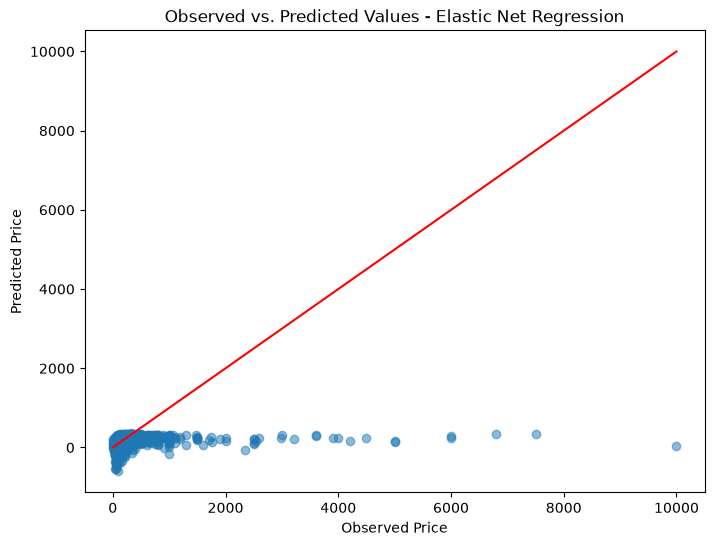

In [70]:
# Observed vs. Predicted Values for the Best-Fit Model
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_elastic, alpha=0.5)
plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()],color="red")

plt.xlabel("Observed Price")
plt.ylabel("Predicted Price")
plt.title("Observed vs. Predicted Values - Elastic Net Regression")

plt.show()

In [71]:
# Elastic Net Regression Equation
print("Intercept:", elastic_model.intercept_)

print("\nCoefficients:")
for feature, coef in zip(X_train_encoded.columns, elastic_model.coef_):
    print(feature, ":", coef)

Intercept: 156.8354372676906

Coefficients:
minimum_nights : -5.427319477028818
number_of_reviews : -16.49105305847319
reviews_per_month : 5.915942744515648
availability_365 : 29.555709525039315
room_type_Private room : -58.92488927328972
room_type_Shared room : -22.535946145645376
neighbourhood_group_Brooklyn : 2.397275659620573
neighbourhood_group_Manhattan : 30.35737920855009
neighbourhood_group_Queens : -5.3917651094937655
neighbourhood_group_Staten Island : -0.8101587370146536


## Classification Model

### Classifying target variable 

In [57]:
# Create Categorical Target Variable
median_price = dataset["price"].median()
dataset["Price_Category"] = np.where(dataset["price"] > median_price, 1, 0)

print("Median Price:", median_price)
print("\nPrice Category Counts:")
print(dataset["Price_Category"].value_counts())

Median Price: 106.0

Price Category Counts:
Price_Category
0    24472
1    24423
Name: count, dtype: int64


### Bulding classification models 

#### 1. Define Independent and Dependent Variables

In [58]:
X_class = dataset[["minimum_nights", "number_of_reviews",
"reviews_per_month", "availability_365","room_type", "neighbourhood_group"]]

y_class = dataset["Price_Category"]

print(X_class.head())
print(y_class.head())

   minimum_nights  number_of_reviews  reviews_per_month  availability_365  \
0               1                  9               0.21               365   
1               1                 45               0.38               355   
2               3                  0                NaN               365   
3               1                270               4.64               194   
4              10                  9               0.10                 0   

         room_type neighbourhood_group  
0     Private room            Brooklyn  
1  Entire home/apt           Manhattan  
2     Private room           Manhattan  
3  Entire home/apt            Brooklyn  
4  Entire home/apt           Manhattan  
0    1
1    1
2    1
3    0
4    0
Name: Price_Category, dtype: int64


#### 2. Splitting the Dataset

In [59]:
from sklearn.model_selection import train_test_split

X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(X_class, y_class, test_size=0.25, random_state=0)

print("X_train:", X_train_class.shape)
print("X_test:", X_test_class.shape)
print("y_train:", y_train_class.shape)
print("y_test:", y_test_class.shape)

X_train: (36671, 6)
X_test: (12224, 6)
y_train: (36671,)
y_test: (12224,)


#### 3. Handling Missing Values

In [60]:
reviews_mean_class = X_train_class["reviews_per_month"].mean()

X_train_class["reviews_per_month"] = X_train_class["reviews_per_month"].fillna(reviews_mean_class)
X_test_class["reviews_per_month"] = X_test_class["reviews_per_month"].fillna(reviews_mean_class)

print("Training Mean:", reviews_mean_class)

print("\nMissing Values in X_train:")
print(X_train_class.isnull().sum())

print("\nMissing Values in X_test:")
print(X_test_class.isnull().sum())

Training Mean: 1.3836447924178426

Missing Values in X_train:
minimum_nights         0
number_of_reviews      0
reviews_per_month      0
availability_365       0
room_type              0
neighbourhood_group    0
dtype: int64

Missing Values in X_test:
minimum_nights         0
number_of_reviews      0
reviews_per_month      0
availability_365       0
room_type              0
neighbourhood_group    0
dtype: int64


#### 4. Encoding Categorical Variables

In [61]:
X_train_class = pd.get_dummies(X_train_class,columns=["room_type", "neighbourhood_group"],drop_first=True)
X_test_class = pd.get_dummies(X_test_class,columns=["room_type", "neighbourhood_group"],drop_first=True)

X_train_class, X_test_class = X_train_class.align( X_test_class, join="left", axis=1, fill_value=0)

print("X_train after encoding:", X_train_class.shape)
print("X_test after encoding:", X_test_class.shape)
print("\nEncoded Features:")
print(X_train_class.columns)

X_train after encoding: (36671, 10)
X_test after encoding: (12224, 10)

Encoded Features:
Index(['minimum_nights', 'number_of_reviews', 'reviews_per_month',
       'availability_365', 'room_type_Private room', 'room_type_Shared room',
       'neighbourhood_group_Brooklyn', 'neighbourhood_group_Manhattan',
       'neighbourhood_group_Queens', 'neighbourhood_group_Staten Island'],
      dtype='str')


#### 5. Feature Scaling

In [62]:
from sklearn.preprocessing import StandardScaler

sc_class = StandardScaler()

X_train_class_scaled = sc_class.fit_transform(X_train_class)
X_test_class_scaled = sc_class.transform(X_test_class)

print("X_train_scaled:", X_train_class_scaled.shape)
print("X_test_scaled:", X_test_class_scaled.shape)
print("y_train:", y_train_class.shape)
print("y_test:", y_test_class.shape)

X_train_scaled: (36671, 10)
X_test_scaled: (12224, 10)
y_train: (36671,)
y_test: (12224,)


#### 6. Applying Classification Models

##### 6.1 Classification Models

In [63]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

logistic_classifier = LogisticRegression(random_state=0)
logistic_classifier.fit(X_train_class_scaled, y_train_class)

y_pred_logistic = logistic_classifier.predict(X_test_class_scaled)

cm_logistic = confusion_matrix(y_test_class, y_pred_logistic)
accuracy_logistic = accuracy_score(y_test_class, y_pred_logistic)
precision_logistic = precision_score(y_test_class, y_pred_logistic)
recall_logistic = recall_score(y_test_class, y_pred_logistic)
f1_logistic = f1_score(y_test_class, y_pred_logistic)

print("Confusion Matrix:")
print(cm_logistic)
print("Accuracy:", accuracy_logistic)
print("Precision:", precision_logistic)
print("Recall:", recall_logistic)
print("F1-score:", f1_logistic)

Confusion Matrix:
[[4968 1169]
 [1004 5083]]
Accuracy: 0.8222349476439791
Precision: 0.8130198336532309
Recall: 0.8350583210119927
F1-score: 0.8238917254234541


##### 6.2 K-Nearest Neighbors (KNN)

In [64]:
from sklearn.neighbors import KNeighborsClassifier

knn_classifier = KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=2)
knn_classifier.fit(X_train_class_scaled, y_train_class)

y_pred_knn = knn_classifier.predict(X_test_class_scaled)

cm_knn = confusion_matrix(y_test_class, y_pred_knn)
accuracy_knn = accuracy_score(y_test_class, y_pred_knn)
precision_knn = precision_score(y_test_class, y_pred_knn)
recall_knn = recall_score(y_test_class, y_pred_knn)
f1_knn = f1_score(y_test_class, y_pred_knn)

print("Confusion Matrix:")
print(cm_knn)
print("Accuracy:", accuracy_knn)
print("Precision:", precision_knn)
print("Recall:", recall_knn)
print("F1-score:", f1_knn)

Confusion Matrix:
[[4857 1280]
 [1174 4913]]
Accuracy: 0.7992473821989529
Precision: 0.7933150331018892
Recall: 0.8071299490717924
F1-score: 0.8001628664495114


##### 6.3 SVM

In [67]:
from sklearn.svm import SVC

svm_classifier = SVC(kernel='linear', random_state=0)
svm_classifier.fit(X_train_class_scaled, y_train_class)

y_pred_svm = svm_classifier.predict(X_test_class_scaled)

cm_svm = confusion_matrix(y_test_class, y_pred_svm)
accuracy_svm = accuracy_score(y_test_class, y_pred_svm)
precision_svm = precision_score(y_test_class, y_pred_svm)
recall_svm = recall_score(y_test_class, y_pred_svm)
f1_svm = f1_score(y_test_class, y_pred_svm)

print("Confusion Matrix:")
print(cm_svm)
print("Accuracy:", accuracy_svm)
print("Precision:", precision_svm)
print("Recall:", recall_svm)
print("F1-score:", f1_svm)

Confusion Matrix:
[[4961 1176]
 [1017 5070]]
Accuracy: 0.8205988219895288
Precision: 0.8117195004803074
Recall: 0.8329226219812715
F1-score: 0.8221843833617125


##### 6.4 Decision Tree

In [68]:
from sklearn.tree import DecisionTreeClassifier

dt_classifier = DecisionTreeClassifier(criterion='entropy', random_state=0)
dt_classifier.fit(X_train_class_scaled, y_train_class)

y_pred_dt = dt_classifier.predict(X_test_class_scaled)

cm_dt = confusion_matrix(y_test_class, y_pred_dt)
accuracy_dt = accuracy_score(y_test_class, y_pred_dt)
precision_dt = precision_score(y_test_class, y_pred_dt)
recall_dt = recall_score(y_test_class, y_pred_dt)
f1_dt = f1_score(y_test_class, y_pred_dt)

print("Confusion Matrix:")
print(cm_dt)
print("Accuracy:", accuracy_dt)
print("Precision:", precision_dt)
print("Recall:", recall_dt)
print("F1-score:", f1_dt)

Confusion Matrix:
[[4687 1450]
 [1574 4513]]
Accuracy: 0.7526178010471204
Precision: 0.7568338084856616
Recall: 0.741416132741909
F1-score: 0.749045643153527


##### 6.5 Random Forest

In [72]:
from sklearn.ensemble import RandomForestClassifier

rf_classifier = RandomForestClassifier(n_estimators=100, criterion='entropy', random_state=0)
rf_classifier.fit(X_train_class_scaled, y_train_class)

y_pred_rf = rf_classifier.predict(X_test_class_scaled)

cm_rf = confusion_matrix(y_test_class, y_pred_rf)
accuracy_rf = accuracy_score(y_test_class, y_pred_rf)
precision_rf = precision_score(y_test_class, y_pred_rf)
recall_rf = recall_score(y_test_class, y_pred_rf)
f1_rf = f1_score(y_test_class, y_pred_rf)

print("Confusion Matrix:")
print(cm_rf)
print("Accuracy:", accuracy_rf)
print("Precision:", precision_rf)
print("Recall:", recall_rf)
print("F1-score:", f1_rf)

Confusion Matrix:
[[4899 1238]
 [1173 4914]]
Accuracy: 0.8027650523560209
Precision: 0.7987646293888166
Recall: 0.8072942336126171
F1-score: 0.8030067815998039


###### Comparison Table

In [73]:
# Classification Model Comparison Table

classification_results = pd.DataFrame({
"Model": [ "Logistic Regression","K-Nearest Neighbors","Support Vector Machine","Decision Tree",
           "Random Forest"],
"Confusion Matrix": [cm_logistic,cm_knn,cm_svm,cm_dt,cm_rf],
"Errors (FP + FN)": [cm_logistic[0,1] + cm_logistic[1,0],cm_knn[0,1] + cm_knn[1,0],cm_svm[0,1] 
                     + cm_svm[1,0],cm_dt[0,1] + cm_dt[1,0],cm_rf[0,1] + cm_rf[1,0]],
"Accuracy": [accuracy_logistic,accuracy_knn,accuracy_svm,accuracy_dt,accuracy_rf],
"Precision": [precision_logistic, precision_knn,precision_svm,precision_dt,precision_rf],
"Recall": [recall_logistic,recall_knn,recall_svm,recall_dt,recall_rf],
"F1-score": [f1_logistic,f1_knn,f1_svm,f1_dt,f1_rf]})

print(classification_results)

                    Model              Confusion Matrix  Errors (FP + FN)  \
0     Logistic Regression  [[4968, 1169], [1004, 5083]]              2173   
1     K-Nearest Neighbors  [[4857, 1280], [1174, 4913]]              2454   
2  Support Vector Machine  [[4961, 1176], [1017, 5070]]              2193   
3           Decision Tree  [[4687, 1450], [1574, 4513]]              3024   
4           Random Forest  [[4899, 1238], [1173, 4914]]              2411   

   Accuracy  Precision    Recall  F1-score  
0  0.822235   0.813020  0.835058  0.823892  
1  0.799247   0.793315  0.807130  0.800163  
2  0.820599   0.811720  0.832923  0.822184  
3  0.752618   0.756834  0.741416  0.749046  
4  0.802765   0.798765  0.807294  0.803007  


##### Best-Fit Classifier

In [74]:
best_classifier = classification_results.loc[classification_results["F1-score"].idxmax()]

print("Best-Fit Classifier:", best_classifier["Model"])
print("Accuracy:", best_classifier["Accuracy"])
print("Precision:", best_classifier["Precision"])
print("Recall:", best_classifier["Recall"])
print("F1-score:", best_classifier["F1-score"])

Best-Fit Classifier: Logistic Regression
Accuracy: 0.8222349476439791
Precision: 0.8130198336532309
Recall: 0.8350583210119927
F1-score: 0.8238917254234541


#### No of elements on the target variable 

In [75]:
# Number of Elements in Each Category Based on Best-Fit Classifier
predicted_categories = pd.Series(y_pred_logistic)
category_counts = predicted_categories.value_counts().sort_index()

print("Best-Fit Classifier: Logistic Regression")
print("\nNumber of Elements in Each Predicted Category:")
print("Low Price (0):", category_counts[0])
print("High Price (1):", category_counts[1])

Best-Fit Classifier: Logistic Regression

Number of Elements in Each Predicted Category:
Low Price (0): 5972
High Price (1): 6252


## Cluster Analysis

### Building the Cluster Analysis

#### 1. Selecting Features for Clustering

In [76]:
# Select Features for Clustering
cluster_data = dataset[["price","minimum_nights","number_of_reviews","reviews_per_month","availability_365"]].copy()

print(cluster_data.head())
print("\nShape:", cluster_data.shape)
print("\nMissing Values:")
print(cluster_data.isnull().sum())

   price  minimum_nights  number_of_reviews  reviews_per_month  \
0    149               1                  9               0.21   
1    225               1                 45               0.38   
2    150               3                  0                NaN   
3     89               1                270               4.64   
4     80              10                  9               0.10   

   availability_365  
0               365  
1               355  
2               365  
3               194  
4                 0  

Shape: (48895, 5)

Missing Values:
price                    0
minimum_nights           0
number_of_reviews        0
reviews_per_month    10052
availability_365         0
dtype: int64


#### 2: Data Preprocessing

In [77]:
# Handling Missing Values
reviews_mean_cluster = cluster_data["reviews_per_month"].mean()
cluster_data["reviews_per_month"] = cluster_data["reviews_per_month"].fillna(reviews_mean_cluster)

print("Mean of reviews_per_month:", reviews_mean_cluster)
print("\nMissing Values After Handling:")
print(cluster_data.isnull().sum())

Mean of reviews_per_month: 1.3732214298586616

Missing Values After Handling:
price                0
minimum_nights       0
number_of_reviews    0
reviews_per_month    0
availability_365     0
dtype: int64


#### 3:Feature Scaling

In [78]:
from sklearn.preprocessing import StandardScaler

cluster_scaler = StandardScaler()
cluster_data_scaled = cluster_scaler.fit_transform(cluster_data)

print("Scaled Data Shape:", cluster_data_scaled.shape)
print("\nFirst 5 Scaled Records:")
print(cluster_data_scaled[:5])

Scaled Data Shape: (48895, 5)

First 5 Scaled Records:
[[-0.01549307 -0.29399621 -0.32041358 -0.77664098  1.91625031]
 [ 0.30097355 -0.29399621  0.48766493 -0.66313811  1.84027456]
 [-0.01132904 -0.19648442 -0.52243321  0.          1.91625031]
 [-0.26533513 -0.29399621  5.53815562  2.18111018  0.61706497]
 [-0.30281144  0.14480686 -0.32041358 -0.85008401 -0.85686461]]


#### 4. Determine optimal num of clusters

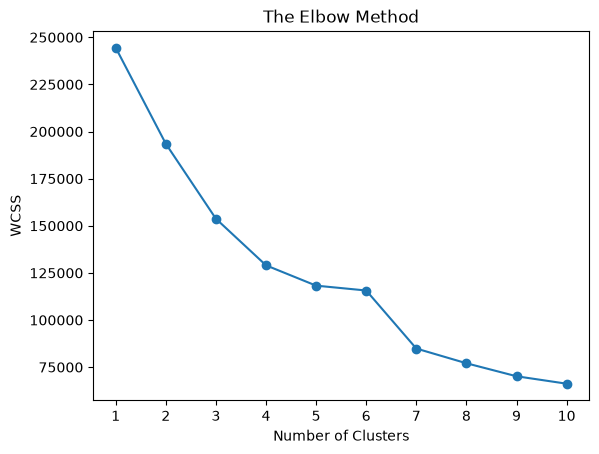

In [79]:
from sklearn.cluster import KMeans
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(cluster_data_scaled)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.title('The Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.xticks(range(1, 11))
plt.show()

#### 5. K-Means Clustering

In [80]:
# Apply K-Means Clustering
kmeans = KMeans(n_clusters=7, init='k-means++', random_state=42)
y_kmeans = kmeans.fit_predict(cluster_data_scaled)
cluster_data["Cluster"] = y_kmeans

print("Cluster Labels:")
print(y_kmeans)

print("\nNumber of Elements in Each Cluster:")
print(cluster_data["Cluster"].value_counts().sort_index())

Cluster Labels:
[4 4 4 ... 1 1 1]

Number of Elements in Each Cluster:
Cluster
0     3971
1    26983
2      124
3       78
4     9685
5     2608
6     5446
Name: count, dtype: int64


#### 6:PCA

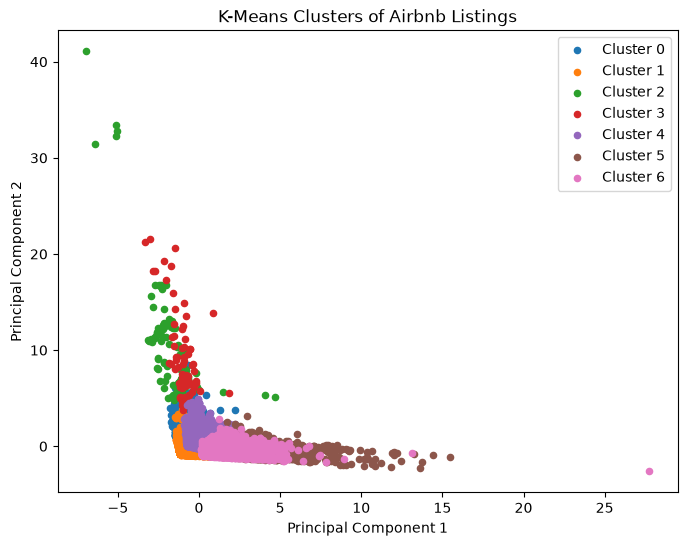

In [81]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
cluster_pca = pca.fit_transform(cluster_data_scaled)
plt.figure(figsize=(8, 6))

for i in range(7):
    plt.scatter(cluster_pca[y_kmeans == i, 0],cluster_pca[y_kmeans == i, 1], s=20,label=f"Cluster {i}")

plt.title("K-Means Clusters of Airbnb Listings")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.show()

#### 7. Cluster Analysis

In [82]:
# Analyze Each Cluster

cluster_analysis = cluster_data.groupby("Cluster")[
["price", "minimum_nights", "number_of_reviews","reviews_per_month", "availability_365"]].mean().round(2)
cluster_analysis["Number of Listings"] = cluster_data["Cluster"].value_counts().sort_index()

print("Cluster Analysis:")
print(cluster_analysis)

Cluster Analysis:
           price  minimum_nights  number_of_reviews  reviews_per_month  \
Cluster                                                                  
0         175.35           34.01               6.00               0.81   
1         136.22            4.50               8.26               0.77   
2         208.79          302.40              12.44               0.93   
3        4461.81           20.05               2.92               1.12   
4         175.41            2.96              19.70               1.18   
5         126.06            2.70             172.60               3.70   
6         127.38            2.31              45.64               4.04   

         availability_365  Number of Listings  
Cluster                                        
0                  274.42                3971  
1                   18.85               26983  
2                  227.72                 124  
3                  188.74                  78  
4                  284.84  

#### 8. Hierarchical Clustering – Dendrogram

In [ ]:
import scipy.cluster.hierarchy as sch
cluster_sample = cluster_data_scaled[:1000]
plt.figure(figsize=(10, 6))

dendrogram = sch.dendrogram(sch.linkage(cluster_sample, method='ward'))

plt.title('Dendrogram - Airbnb Listings')
plt.xlabel('Airbnb Listings')
plt.ylabel('Euclidean Distances')
plt.show()

#### 9: Hierarchical Clustering 

In [ ]:
from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(n_clusters=7, metric='euclidean',linkage='ward')
y_hc = hc.fit_predict(cluster_sample)

print("Hierarchical Cluster Labels:")
print(y_hc)

print("\nNumber of Elements in Each Cluster:")
print(pd.Series(y_hc).value_counts().sort_index())

#### 10.Hierarchical Clustering

In [ ]:
from sklearn.decomposition import PCA
pca_hc = PCA(n_components=2)
hc_pca = pca_hc.fit_transform(cluster_sample)

plt.figure(figsize=(8, 6))

for i in range(7):
    plt.scatter(
        hc_pca[y_hc == i, 0],
        hc_pca[y_hc == i, 1],
        s=20,
        label=f"Cluster {i}"
    )

plt.title("Hierarchical Clusters of Airbnb Listings")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.show()